# ¿Como ejecutar?

- crear entorno virtual de pyhton

    *python -m venv 'nombre del env'*

    *source 'nombre del env'/bin/activate*

- poner en la misma carpeta el archivo 'rice.png'

- ejecutar todas las celdas

- paso 4: disfrutar

In [360]:
!pip install opencv-python
!pip install matplotlib
!pip install pandas
!pip install scipy

In [361]:
import cv2
import matplotlib.pyplot as plt
import pandas as pd
import math
import scipy
import numpy as np

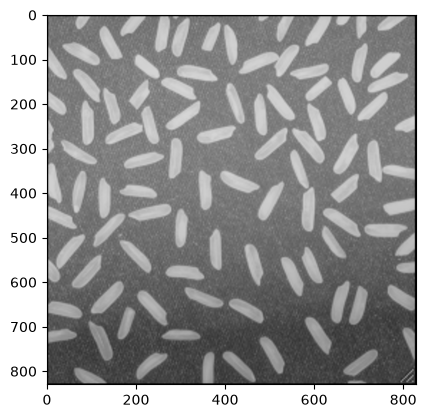

Dimesiones: (830, 830, 3)


In [362]:
img = cv2.imread('rice.png')


plt.figure()
plt.imshow(img)
plt.show()
print("Dimesiones:", img.shape)

#### Funcion de color pormedio definida por el github del profe

In [363]:
def color_promedio(im):
    b, g, r = cv2.split(im)
    area = r.shape[0]*r.shape[1]
    prom_r = np.sum(r)/area 
    prom_g = np.sum(g)/area
    prom_b = np.sum(b)/area
    return   prom_r, prom_g, prom_b 

In [364]:
RojoAvg, VerdeAvg, AzulAvg = color_promedio(img)

print("Promedio de color Rojo:", RojoAvg)
print("Promedio de color Verde:", VerdeAvg)
print("Promedio de color Azul:", AzulAvg)

Promedio de color Rojo: 126.48017128755988
Promedio de color Verde: 126.48017128755988
Promedio de color Azul: 126.48017128755988


### ahora trabajaremos con cada arroz individual

Como ya no necesitamos la imagen a color, la convertimos a escala de grises para poder trabajar con ella y sacar los descriptores correspondientes.

In [365]:
imgGray = cv2.imread('rice.png', cv2.IMREAD_GRAYSCALE)

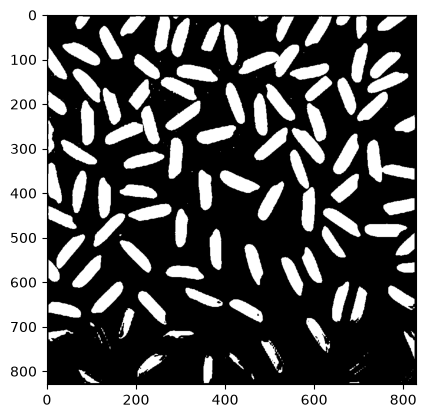

In [366]:
_, imagenBinarizada = cv2.threshold(imgGray, 150, 255, cv2.THRESH_BINARY)

plt.figure()
plt.imshow(imagenBinarizada, cmap='gray')
plt.show()

Sacamos cada grano de arroz por separado

Granos encontrados: 102


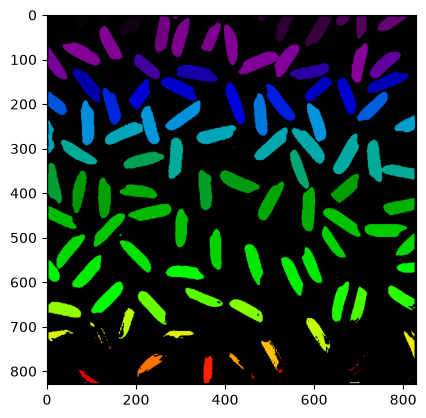

In [367]:
num, labels, stats, centroids = cv2.connectedComponentsWithStats(imagenBinarizada, connectivity=8)

granos = []
granos_identificados = []

areaImagen = 30

for i in range(1, num):        # 0 es el fondo, se salta
    area = stats[i, cv2.CC_STAT_AREA]
    if area < areaImagen:
        continue               # descarta ruido

    x = stats[i, cv2.CC_STAT_LEFT]
    y = stats[i, cv2.CC_STAT_TOP]
    w = stats[i, cv2.CC_STAT_WIDTH]
    h = stats[i, cv2.CC_STAT_HEIGHT]
    
    componente = (labels == i).astype(np.uint8) * 255

    
    recorte = imgGray[y:y+h, x:x+w] 

    granos.append(recorte)
    granos_identificados.append(i)

print(f"Granos encontrados: {len(granos_identificados)}")

plt.imshow(labels, cmap='nipy_spectral')

plt.show()

Sacamos el gradiente promedio con las funcion del github del profe

In [368]:
def gradiente_perimetro(I, J, im):
    
    n = len(I)
    out = 0
    for i in range(0, n):
        out = out + gradiente(I[i],J[i],im)

    return float(out/n)


def gradiente(i,j,L):
    # funcion que calcula el gradiente
    # en la posicion posL de la imagen L
    Lx= -0.5*L[i-1,j]+0.5*L[i+1,j]
    Ly= -0.5*L[i,j-1]+0.5*L[i,j+1]
    out= math.sqrt(Lx**2+Ly**2)
    return out

In [369]:
listaDeGradientes = []

for frag_id in granos_identificados:

    frag = (labels == frag_id).astype(np.uint8) * 255

    cnts, hs = cv2.findContours(frag, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    contornos = np.vstack(cnts[0])
    x , y = zip(*contornos)
    x = np.array(x).astype(int)
    y = np.array(y).astype(int)

    dprom = gradiente_perimetro(y,x, imgGray.astype(float))
    listaDeGradientes.append(dprom)

print(listaDeGradientes)


[29.147733328514086, 28.61747356359901, 25.154955685524218, 20.506107620450994, 21.289443439977134, 42.595912184855514, 26.667222510798844, 21.950502795676684, 20.234057730008193, 18.838786392730704, 19.222999935765625, 18.974717462538322, 19.33289431660309, 20.277551283075873, 18.59691552467141, 19.534449622999656, 18.424337459456545, 27.24353338300098, 19.260163947428165, 17.3161598001717, 17.6397142342094, 17.572533592284746, 19.14913413866199, 18.712174262806638, 18.58332060579108, 16.481042993775862, 19.055787089271966, 18.05921141451037, 16.252398905684895, 18.39433034527926, 17.470044062851343, 30.575021436537444, 18.946014068401773, 17.448196590083104, 19.52047101256564, 18.02185720359568, 18.720617281407936, 17.30521558656355, 35.598279156086925, 34.28381419853389, 17.974888382826244, 16.66482002150539, 19.221871168975806, 19.02651091738427, 18.75115925279019, 17.25130757901627, 17.251245980184628, 18.10706577656682, 18.210784968893087, 17.297609691720304, 38.467529828543356, 

In [370]:
def contraste(im, level):

    #imagen binaria umbralizada
    bw = im>level

    # calculamos el entorno y aplicamos 
    # una negación a la región
    ebw = np.logical_not(bw)

    # calculamos el promedio del entorno
    Ge = np.sum(im[ebw])/np.sum(ebw)
    Gr = np.sum(im[bw])/np.sum(bw)

    K1 = (Gr-Ge)/Ge
    K2 = (Gr-Ge)/(Gr+Ge)
    K3 = np.log(Gr/Ge)
    K = K1, K2, K3
    return K


In [371]:
listaDeContrastesK1 = []
listaDeContrastesK2 = []
listaDeContrastesK3 = []

for i in range(len(granos)):
    
    K = contraste(granos[i], 150)
    listaDeContrastesK1.append(K[0])
    listaDeContrastesK2.append(K[1])
    listaDeContrastesK3.append(K[2])

# Resultados del contraste
print(listaDeContrastesK1)
print(listaDeContrastesK2)
print(listaDeContrastesK3)

[np.float64(0.48015604509718535), np.float64(0.5927345715171773), np.float64(0.3899174204524953), np.float64(0.5034293389602165), np.float64(0.5854733580160947), np.float64(0.5084239115224772), np.float64(0.46947340526957876), np.float64(0.5380828460811735), np.float64(0.5410445900817724), np.float64(0.319249954925176), np.float64(0.5192345481920588), np.float64(0.5268504264310337), np.float64(0.5059560107762568), np.float64(0.5724145925980788), np.float64(0.538127070232042), np.float64(0.5150382679161004), np.float64(0.525700419515046), np.float64(0.541560645116524), np.float64(0.5654485848779379), np.float64(0.5256103241556409), np.float64(0.46733919224857035), np.float64(0.48236739339411994), np.float64(0.5246304879276248), np.float64(0.5241927607312502), np.float64(0.5081246525930592), np.float64(0.48533714065261446), np.float64(0.5237363257391868), np.float64(0.4699342246140837), np.float64(0.46368826795798573), np.float64(0.5329767540967212), np.float64(0.4640863188689399), np.fl

Por ultimo los momentos de Hu (sacados de openCV esta vez pa no copiar todo ese codigo y para no tener que adaptarlo a escala de gris a mano XD)

In [372]:
listaDeMomentosHu1 = []
listaDeMomentosHu2 = []
listaDeMomentosHu3 = []
listaDeMomentosHu4 = []

for i in range(len(granos)):
    huMoments = cv2.HuMoments(cv2.moments(granos[i]))
    for j in range(0,4):
        huMoments[j] = -1* math.copysign(1.0, huMoments[j][0]) * math.log10(np.abs(huMoments[j][0]))
   
    listaDeMomentosHu1.append(huMoments[0])
    listaDeMomentosHu2.append(huMoments[1])
    listaDeMomentosHu3.append(huMoments[2])
    listaDeMomentosHu4.append(huMoments[3])

print(listaDeMomentosHu1)
print(listaDeMomentosHu2)
print(listaDeMomentosHu3)
print(listaDeMomentosHu4)

[array([3.02386887]), array([3.0052476]), array([2.94959406]), array([2.98249867]), array([3.00821305]), array([3.02827483]), array([2.94698124]), array([2.92299301]), array([2.91457567]), array([2.87448737]), array([2.90598518]), array([2.98695282]), array([2.84744883]), array([2.98237419]), array([2.95949166]), array([2.888039]), array([2.91817753]), array([2.93645303]), array([3.01494488]), array([3.03042015]), array([2.88925564]), array([2.91026675]), array([2.98868396]), array([2.93719459]), array([3.01585374]), array([2.98922866]), array([2.93746489]), array([3.00329739]), array([2.89780789]), array([2.99171578]), array([2.92353481]), array([3.02024384]), array([3.00206416]), array([2.83526559]), array([2.81346087]), array([2.99659785]), array([2.93641313]), array([2.92809383]), array([3.03232206]), array([2.58836099]), array([2.96030298]), array([2.93782616]), array([2.99149001]), array([3.00662525]), array([2.96576753]), array([2.85508597]), array([2.96619694]), array([2.954544

In [373]:

filas = [f'Grano{i}' for i in range(1, 103)]

momentos1 = pd.DataFrame(listaDeMomentosHu1, columns=['Hu1'], index=filas)
momentos2 = pd.DataFrame(listaDeMomentosHu2, columns=['Hu2'], index=filas)
momentos3 = pd.DataFrame(listaDeMomentosHu3, columns=['Hu3'], index=filas)
momentos4 = pd.DataFrame(listaDeMomentosHu4, columns=['Hu4'], index=filas)

gradientes = pd.DataFrame(listaDeGradientes, index=filas, columns= ['Gradiente Promedio'])

contraste1 =pd.DataFrame(listaDeContrastesK1, index=filas, columns=['Contraste K1'])
contraste2 =pd.DataFrame(listaDeContrastesK2, index=filas, columns=['Contraste K2'])
contraste3 =pd.DataFrame(listaDeContrastesK3, index=filas, columns=['Contraste K3'])


final = pd.concat([momentos1, momentos2, momentos3, momentos4, gradientes, contraste1, contraste2, contraste3], axis = 1)
    

final.head(36)

,Hu1,Hu2,Hu3,Hu4,Gradiente Promedio,Contraste K1,Contraste K2,Contraste K3
Grano1,3.023869,7.852720,12.358822,11.543635,29.147733,0.480156,0.193599,0.392148
Grano2,3.005248,7.239286,11.719558,11.701590,28.617474,0.592735,0.228614,0.465452
Grano3,2.949594,6.375175,11.201075,11.071076,25.154956,0.389917,0.163151,0.329244
Grano4,2.982499,6.848635,12.008138,11.323104,20.506108,0.503429,0.201096,0.407749
Grano5,3.008213,7.414782,12.082213,13.157565,21.289443,0.585473,0.226447,0.460883
Grano6,3.028275,6.888552,11.947736,11.612523,42.595912,0.508424,0.202687,0.411065
Grano7,2.946981,6.281471,11.210222,11.324718,26.667223,0.469473,0.190111,0.384904
Grano8,2.922993,6.300584,11.192671,11.027226,21.950503,0.538083,0.212004,0.430537
Grano9,2.914576,6.138415,12.322182,12.616202,20.234058,0.541045,0.212922,0.432460
Grano10,2.874487,6.065454,11.416892,11.759177,18.838786,0.319250,0.137652,0.277063
